# CSCI461 - Assignment 1: SMS Spam Analysis

**Dataset:** SMS Spam Collection. Each row is one SMS message and its label (`ham` or `spam`).

**Goal:** Explore the data, clean it, analyze text, train a classifier and perform K-Means clustering.

This notebook uses beginner-friendly Python, Pandas and scikit-learn. Run the cells in order using **Restart Kernel and Run All Cells** inside Docker. The original `text` stays unchanged; cleaning is saved in `cleaned_text`.

## 1. Import libraries and set file paths

We use `pandas` for tables, `matplotlib/seaborn` for plots and `scikit-learn` for machine learning.

Jupyter sometimes starts in the project folder and sometimes in its `notebook` folder. The `if` below supports both.

In [1]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score

if os.path.exists("data/dataset.csv"):
    folder = "."
else:
    folder = ".."

data_file = folder + "/data/dataset.csv"
output_folder = folder + "/output"
figures_folder = output_folder + "/figures"
os.makedirs(figures_folder, exist_ok=True)

print("Dataset path:", data_file)

Dataset path: ../data/dataset.csv


## 2. Understand the dataset

- `text`: the SMS message (text column)
- `label`: spam or ham (category/target column)
- There are no numerical columns at first; we will create numerical features from text.

Show the first records, dataset size, column names, data types and descriptive statistics.

In [2]:
df = pd.read_csv(data_file)

print("First 5 rows:")
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Data types:")
print(df.dtypes)
print("Information:")
df.info()
print("Statistics:")
display(df.describe(include="all"))
print("Ham and spam counts:")
print(df["label"].value_counts())

First 5 rows:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Shape: (5574, 2)
Columns: ['label', 'text']
Data types:
label    str
text     str
dtype: object
Information:
<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5574 non-null   str  
 1   text    5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB
Statistics:


,label,text
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


Ham and spam counts:
label
ham     4827
spam     747
Name: count, dtype: int64


## 3. Missing values and duplicates

First check missing values and duplicate rows. We replace missing message text with empty strings, remove empty messages and invalid labels, then remove repeated `(label, text)` rows.

**Reason:** Empty text cannot be analyzed, and keeping duplicate messages can make training/test evaluation misleading. The original CSV file remains unchanged.

In [3]:
print("Missing values before cleaning:")
print(df.isnull().sum())
print("Duplicate rows before cleaning:", df.duplicated().sum())
print("Shape before cleaning:", df.shape)

# Clean labels and handle missing messages
df["label"] = df["label"].str.lower().str.strip()
df["text"] = df["text"].fillna("")

df = df[df["label"].isin(["ham", "spam"])]
df = df[df["text"].str.strip() != ""]
df = df.drop_duplicates(subset=["label", "text"])
df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Missing values after cleaning:")
print(df.isnull().sum())
print("Duplicates after cleaning:", df.duplicated().sum())

Missing values before cleaning:
label    0
text     0
dtype: int64
Duplicate rows before cleaning: 403
Shape before cleaning: (5574, 2)
Shape after cleaning: (5171, 2)
Missing values after cleaning:
label    0
text     0
dtype: int64
Duplicates after cleaning: 0


## 4. `loc`, `iloc` and `np.r_`

`loc` selects rows based on conditions. `iloc` selects rows by their numbers. `np.r_` combines different row positions.

In [4]:
# loc: spam messages that are longer than 160 characters
spam_long = df.loc[(df["label"] == "spam") & (df["text"].str.len() > 160)]
display(spam_long.head())

# iloc: first 3 rows, first 2 columns
display(df.iloc[0:3, 0:2])

# np.r_: first 3 and last 3 rows
rows = np.r_[0:3, len(df)-3:len(df)]
display(df.iloc[rows, 0:2])

,label,text
42,spam,07732584351 - Rodger Burns - MSG = We tried to...
56,spam,Congrats! 1 year special cinema pass for 2 is ...
134,spam,Want 2 get laid tonight? Want real Dogging loc...
360,spam,"Update_Now - Xmas Offer! Latest Motorola, Sony..."
415,spam,Someone has contacted our dating service and e...


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5168,ham,"Pity, * was in mood for that. So...any other s..."
5169,ham,The guy did some bitching but I acted like i'd...
5170,ham,Rofl. Its true to its name


## 5. Transformations and new features

We do at least three transformations:

1. **Encoding:** convert `spam` to 1 and `ham` to 0 in `is_spam`.
2. **Feature creation:** message length, number of words, unique words, average word length and digits.
3. **Binning:** divide message lengths into short, medium and long.
4. **Normalization:** divide word count by the maximum word count.

These features help us analyze how messages differ.

In [5]:
# Convert the label to a number
df["is_spam"] = (df["label"] == "spam").astype(int)

# Get a list of words for each message
word_lists = df["text"].str.lower().str.findall("[a-z]+")

df["char_count"] = df["text"].str.len()
df["word_count"] = word_lists.apply(len)
df["unique_word_count"] = word_lists.apply(lambda words: len(set(words)))

# A small function to calculate average word length
def average_word_length(words):
    if len(words) == 0:
        return 0
    total = 0
    for word in words:
        total = total + len(word)
    return total / len(words)

df["avg_word_length"] = word_lists.apply(average_word_length)
df["digit_count"] = df["text"].str.count("[0-9]")

# Group messages by length
df["length_group"] = pd.cut(df["char_count"], bins=[0, 60, 140, float("inf")],
                            labels=["short", "medium", "long"])

# Normalized word count, between 0 and 1
df["normalized_words"] = df["word_count"] / df["word_count"].max()

display(df.head())

,label,text,is_spam,char_count,word_count,unique_word_count,avg_word_length,digit_count,length_group,normalized_words
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20,20,4.150000,0,medium,0.105263
1,ham,Ok lar... Joking wif u oni...,0,29,6,6,3.000000,0,short,0.031579
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,30,25,3.233333,25,long,0.157895
3,ham,U dun say so early hor... U c already then say...,0,49,11,9,3.000000,0,short,0.057895
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,14,13,3.357143,0,medium,0.073684


## 6. Sampling

**Simple random sampling:** randomly select 500 messages.

**Stratified sampling:** select ham and spam messages separately, approximately in their original proportions.

**Cluster sampling:** divide messages into 4 groups based on message length and randomly select one entire group. These groups are made for this sampling exercise (the dataset does not have natural cluster IDs). Cluster sampling is **different** from K-Means clustering.

The random sample can have slightly different label percentages by chance. The stratified sample keeps the percentages close to the full dataset. A cluster sample can be very different because it selects **all messages in one length group**, not individual messages from everywhere.


Selected sampling group: Group 3


,method,size,ham_%,spam_%
0,Original,5171,87.37,12.63
1,Random,500,87.80,12.20
2,Stratified,500,87.40,12.60
3,Cluster,1292,92.72,7.28


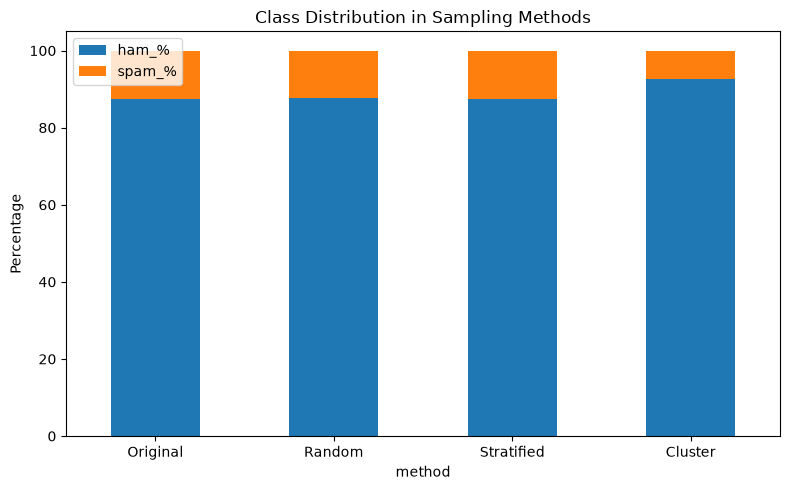

In [6]:
# Simple random sample
random_sample = df.sample(n=500, random_state=42)

# Stratified sample: preserve approximately the same percentage of ham/spam
ham = df[df["label"] == "ham"]
spam = df[df["label"] == "spam"]
ham_number = round(500 * len(ham) / len(df))
spam_number = 500 - ham_number

ham_sample = ham.sample(n=ham_number, random_state=42)
spam_sample = spam.sample(n=spam_number, random_state=42)
stratified_sample = pd.concat([ham_sample, spam_sample])

# Cluster sample: one whole group of similarly sized messages
df["sampling_cluster"] = pd.qcut(df["char_count"].rank(method="first"), 4,
                                 labels=["Group 1", "Group 2", "Group 3", "Group 4"])
np.random.seed(42)
selected_group = np.random.choice(["Group 1", "Group 2", "Group 3", "Group 4"])
cluster_sample = df[df["sampling_cluster"] == selected_group]
print("Selected sampling group:", selected_group)

# Compare ham/spam percentages
sample_names = ["Original", "Random", "Stratified", "Cluster"]
sample_tables = [df, random_sample, stratified_sample, cluster_sample]
sample_results = []

for i in range(4):
    sample = sample_tables[i]
    ham_percent = (sample["label"] == "ham").mean() * 100
    spam_percent = (sample["label"] == "spam").mean() * 100
    sample_results.append([sample_names[i], len(sample), ham_percent, spam_percent])

sample_results = pd.DataFrame(sample_results, columns=["method", "size", "ham_%", "spam_%"])
display(sample_results.round(2))

sample_results.plot(x="method", y=["ham_%", "spam_%"], kind="bar", stacked=True, figsize=(8, 5))
plt.ylabel("Percentage")
plt.title("Class Distribution in Sampling Methods")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_folder + "/sampling_class_distributions.png")
plt.show()

## 7. Correlation

Create a correlation matrix using at least four numerical text features. Values near +1 or -1 show a strong relationship; values near 0 show a weak linear relationship.

**Correlation does not mean causation:** two values may change together without one directly causing the other.

**Result interpretation:** `char_count` and `word_count` have a strong positive correlation (about **0.97**), because longer messages generally contain more words. `avg_word_length` and `digit_count` have a weak positive correlation (about **0.16**). Neither result proves a cause-and-effect relationship.


                   char_count  word_count  unique_word_count  avg_word_length  \
char_count               1.00        0.97               0.96             0.13   
word_count               0.97        1.00               0.97            -0.01   
unique_word_count        0.96        0.97               1.00             0.00   
avg_word_length          0.13       -0.01               0.00             1.00   
digit_count              0.38        0.24               0.29             0.16   

                   digit_count  
char_count                0.38  
word_count                0.24  
unique_word_count         0.29  
avg_word_length           0.16  
digit_count               1.00  


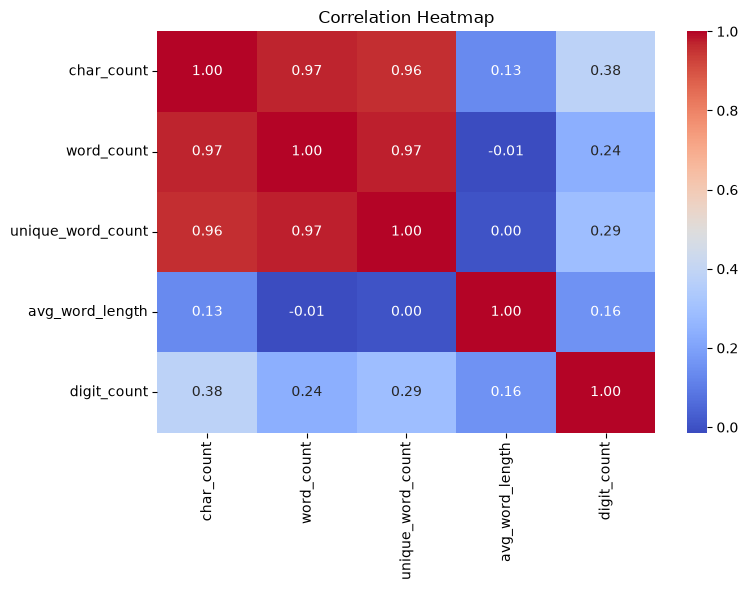

Character count and word count correlation: 0.97
Average word length and digit count correlation: 0.16


In [7]:
columns = ["char_count", "word_count", "unique_word_count", "avg_word_length", "digit_count"]
correlation = df[columns].corr()
print(correlation.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(figures_folder + "/correlation_heatmap.png")
plt.show()

print("Character count and word count correlation:", round(correlation.loc["char_count", "word_count"], 2))
print("Average word length and digit count correlation:", round(correlation.loc["avg_word_length", "digit_count"], 2))

## 8. Clean text and tokenize

Do not replace the original `text`. Create a new `cleaned_text` column. Convert to lowercase, replace URLs and numbers with words, remove punctuation and extra spaces. Then split the text into words (tokens).

In [8]:
def clean_message(message):
    message = message.lower()
    message = re.sub(r"https?://\S+|www\.\S+", " url ", message)
    message = re.sub(r"[0-9]+", " number ", message)
    message = re.sub(r"[^a-z ]", " ", message)
    message = " ".join(message.split())
    return message

df["cleaned_text"] = df["text"].apply(clean_message)
df["tokens"] = df["cleaned_text"].str.split()

all_words = " ".join(df["cleaned_text"]).split()
word_counts = Counter(all_words)

print("Total tokens:", len(all_words))
print("Unique words:", len(word_counts))
print("Average words per message:", round(len(all_words) / len(df), 2))
display(df[["text", "cleaned_text", "tokens"]].head())

Total tokens: 84003
Unique words: 7740
Average words per message: 16.25


,text,cleaned_text,tokens
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,"[go, until, jurong, point, crazy, available, o..."
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in number a wkly comp to win fa cup...,"[free, entry, in, number, a, wkly, comp, to, w..."
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t..."
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,"[nah, i, don, t, think, he, goes, to, usf, he,..."


## 9. Top 20 frequent words

Find the 20 most common words. Some common words like *the* and *to* are stop words, so compare results before and after removing English stop words.

,word,count
0,number,4018
1,i,2860
2,you,2150
3,to,2080
4,a,1325
5,the,1249
6,u,1090
7,and,930
8,in,835
9,is,800


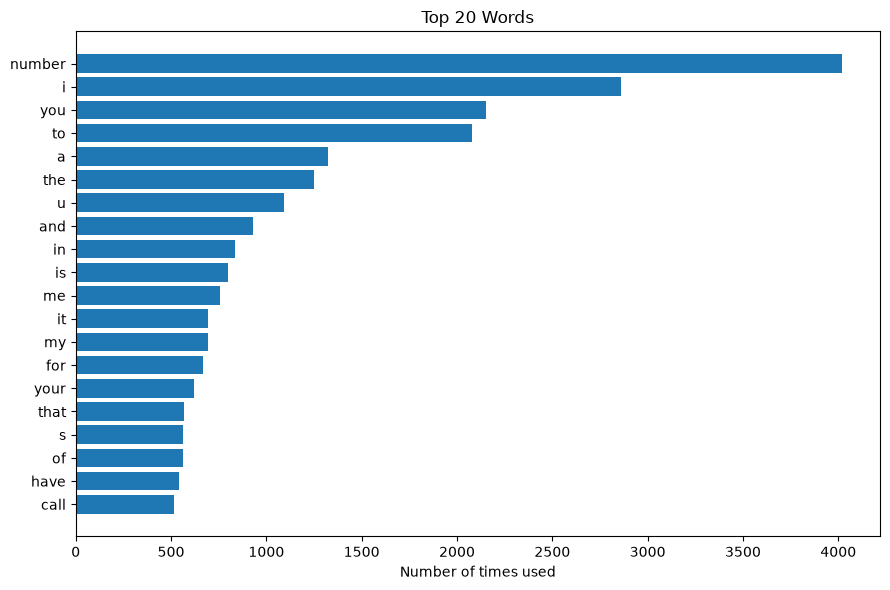

,word,count
0,number,4018
1,u,1090
2,s,565
3,t,468
4,m,440
5,just,350
6,ur,322
7,gt,288
8,lt,287
9,ok,261


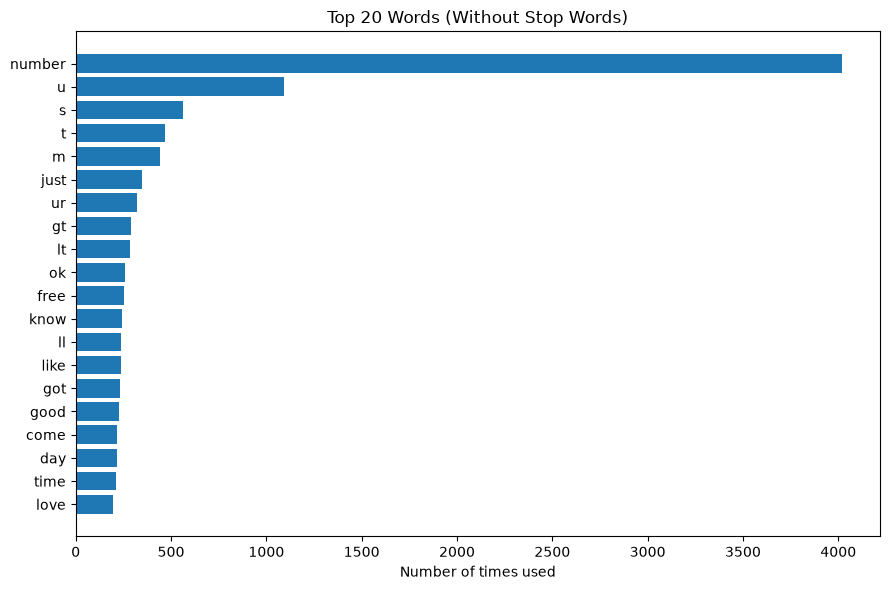

In [9]:
# Most common words before stop-word removal
top20 = pd.DataFrame(word_counts.most_common(20), columns=["word", "count"])
display(top20)

plt.figure(figsize=(9, 6))
plt.barh(top20["word"], top20["count"])
plt.gca().invert_yaxis()
plt.title("Top 20 Words")
plt.xlabel("Number of times used")
plt.tight_layout()
plt.savefig(figures_folder + "/top20_word_frequency.png")
plt.show()

# Remove stop words for the second comparison
words_no_stop = []
for word in all_words:
    if word not in ENGLISH_STOP_WORDS:
        words_no_stop.append(word)

top20_no_stop = pd.DataFrame(Counter(words_no_stop).most_common(20),
                             columns=["word", "count"])
display(top20_no_stop)

plt.figure(figsize=(9, 6))
plt.barh(top20_no_stop["word"], top20_no_stop["count"])
plt.gca().invert_yaxis()
plt.title("Top 20 Words (Without Stop Words)")
plt.xlabel("Number of times used")
plt.tight_layout()
plt.savefig(figures_folder + "/top20_without_stopwords.png")
plt.show()

## 10. Compare ham and spam

Compare their average character length, average word count and top 10 non-stop words. This helps explain differences between the two types of messages.

,char_count,word_count
label,,
ham,70.89,14.48
spam,137.71,22.85


Top 10 words for ham


,word,count
0,number,1188
1,u,938
2,s,481
3,m,397
4,t,388
5,gt,288
6,lt,287
7,just,282
8,ok,256
9,ll,233


Top 10 words for spam


,word,count
0,number,2830
1,free,197
2,p,158
3,u,152
4,txt,138
5,ur,119
6,stop,116
7,mobile,111
8,text,108
9,claim,96


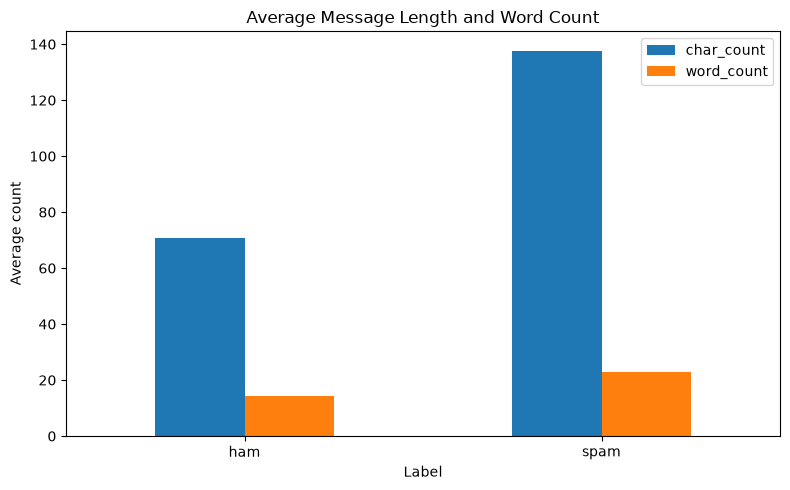

In [10]:
group_averages = df.groupby("label")[["char_count", "word_count"]].mean()
display(group_averages.round(2))

# Top 10 words in each class
for label in ["ham", "spam"]:
    messages = df[df["label"] == label]["cleaned_text"]
    words = " ".join(messages).split()
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]
    top10 = pd.DataFrame(Counter(words).most_common(10), columns=["word", "count"])
    print("Top 10 words for", label)
    display(top10)

# Comparison plot
group_averages.plot(kind="bar", figsize=(8, 5))
plt.title("Average Message Length and Word Count")
plt.ylabel("Average count")
plt.xlabel("Label")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_folder + "/group_text_comparison.png")
plt.show()

## 11. Five insights (observation, evidence, interpretation)

**Insight 1 - Class imbalance**
- **Observation:** There are more ham messages than spam messages.
- **Evidence:** After cleaning, we have 4,518 ham messages and 653 spam messages (about 87% ham and 13% spam).
- **Interpretation:** Accuracy alone could be misleading. We also need spam precision, recall and F1-score.

**Insight 2 - Message length**
- **Observation:** Spam messages tend to be longer.
- **Evidence:** The average length is 137.71 characters for spam, versus 70.89 for ham.
- **Interpretation:** Length may help identify spam, but it cannot classify every message by itself.

**Insight 3 - Number of words**
- **Observation:** Spam messages contain more words on average.
- **Evidence:** Spam has an average of 22.85 alphabetic words, compared with 14.48 for ham.
- **Interpretation:** Different message types have different writing patterns, so text features can be useful.

**Insight 4 - Digits in messages**
- **Observation:** Spam messages contain digits much more often.
- **Evidence:** About 94.0% of spam messages contain at least one digit, compared with 15.8% of ham messages.
- **Interpretation:** Spam may include numbers for contact details, prices or offers. The presence of a number does not prove a message is spam.

**Insight 5 - Frequent words**
- **Observation:** The vocabulary differs between ham and spam, and cleaning can change the word frequencies.
- **Evidence:** The `number` placeholder appears 4,018 times overall after cleaning; terms such as `free`, `txt` and `claim` appear among the top spam words after stop-word removal.
- **Interpretation:** Frequent words can help explain categories, but the `number` placeholder represents original numbers and is not a literal word in the original messages.


## 12. Supervised Machine Learning: TF-IDF + Classification

1. Split messages into 80% training and 20% testing, with `stratify` to keep the original label proportions.
2. Use TF-IDF to convert text into numbers. **Fit TF-IDF on training messages only**, then transform test messages.
3. Train Logistic Regression and evaluate accuracy, precision, recall, F1 and a confusion matrix.
4. For the bonus, compare a second classifier: Multinomial Naive Bayes.

**Limitation:** This dataset is old and unbalanced, so a good test score does not guarantee the model will work on new kinds of spam.

Logistic Regression results:
Accuracy: 0.9807
Spam Precision: 0.9111
Spam Recall: 0.9389
Spam F1: 0.9248
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.91      0.94      0.92       131

    accuracy                           0.98      1035
   macro avg       0.95      0.96      0.96      1035
weighted avg       0.98      0.98      0.98      1035



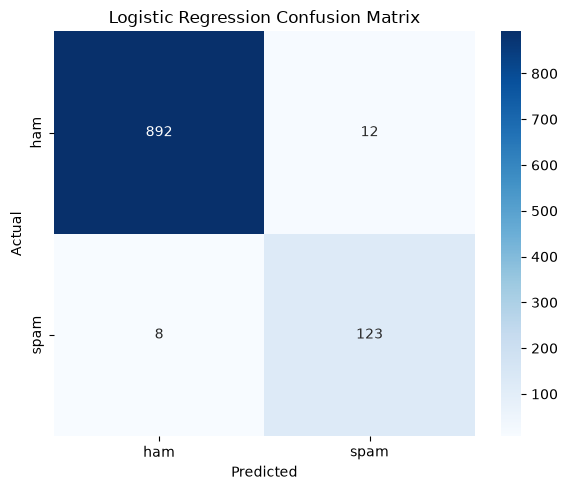

Naive Bayes results:
Accuracy: 0.9778
Spam F1: 0.9046
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       904
        spam       0.99      0.83      0.90       131

    accuracy                           0.98      1035
   macro avg       0.98      0.92      0.95      1035
weighted avg       0.98      0.98      0.98      1035



In [11]:
# Split the messages into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    df["cleaned_text"], df["label"], test_size=0.2, random_state=42,
    stratify=df["label"]
)

# Convert text into TF-IDF numbers
tfidf = TfidfVectorizer(max_features=5000, min_df=2)
X_train_numbers = tfidf.fit_transform(X_train)
X_test_numbers = tfidf.transform(X_test)

# Model 1: Logistic Regression
model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model.fit(X_train_numbers, y_train)
predictions = model.predict(X_test_numbers)

print("Logistic Regression results:")
print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Spam Precision:", round(precision_score(y_test, predictions, pos_label="spam"), 4))
print("Spam Recall:", round(recall_score(y_test, predictions, pos_label="spam"), 4))
print("Spam F1:", round(f1_score(y_test, predictions, pos_label="spam"), 4))
print(classification_report(y_test, predictions))

# Confusion matrix
matrix = confusion_matrix(y_test, predictions, labels=["ham", "spam"])
plt.figure(figsize=(6, 5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig(figures_folder + "/supervised_confusion_matrix.png")
plt.show()

# Model 2: Naive Bayes (bonus comparison)
naive_bayes = MultinomialNB()
naive_bayes.fit(X_train_numbers, y_train)
nb_predictions = naive_bayes.predict(X_test_numbers)

print("Naive Bayes results:")
print("Accuracy:", round(accuracy_score(y_test, nb_predictions), 4))
print("Spam F1:", round(f1_score(y_test, nb_predictions, pos_label="spam"), 4))
print(classification_report(y_test, nb_predictions))

## 13. K-Means (Unsupervised Clustering)

Unlike classification, K-Means does **not** use `label` during training. We choose `k=2` as an understandable starting point because the dataset has two known categories, but the clusters may not match ham/spam.

We measure cluster sizes and a sampled silhouette score, inspect the top words in each cluster, and compare their labels **after** clustering. Cluster numbers are arbitrary.

**Result interpretation:** One cluster contains words often seen in promotional messages, including `free`, `call` and `claim`. The other has more ordinary conversational terms. The sampled cosine silhouette score is about **0.019**, which suggests that the two text groups are not strongly separated. The learned clusters do not have to match the known classes perfectly.


Messages in each cluster:
cluster
0    4506
1     665
Name: count, dtype: int64
Silhouette score: 0.019
Cluster 0 top words: you, to, the, in, me, and, it, my, is, number
Cluster 1 top words: number, to, call, free, your, or, txt, now, you, claim


label,ham,spam
cluster,,
0,4376,130
1,142,523


Ham/spam percentages per cluster:


label,ham,spam
cluster,,
0,97.11,2.89
1,21.35,78.65


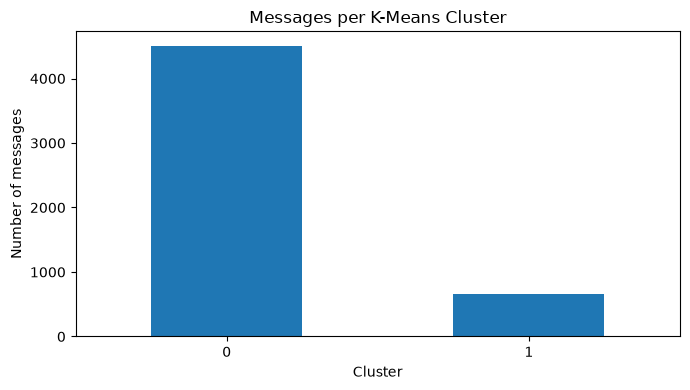

In [12]:
# TF-IDF for clustering
cluster_tfidf = TfidfVectorizer(max_features=5000, min_df=2)
X_cluster = cluster_tfidf.fit_transform(df["cleaned_text"])

# K-Means does not receive the correct labels
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_cluster)

print("Messages in each cluster:")
cluster_sizes = df["cluster"].value_counts().sort_index()
print(cluster_sizes)

# Silhouette is calculated on a smaller sample to run faster
score = silhouette_score(X_cluster, df["cluster"], sample_size=300,
                         random_state=42, metric="cosine")
print("Silhouette score:", round(score, 4))

# Find the important words for each cluster
feature_names = cluster_tfidf.get_feature_names_out()
for i in range(2):
    top_positions = kmeans.cluster_centers_[i].argsort()[-10:][::-1]
    important_words = feature_names[top_positions]
    print("Cluster", i, "top words:", ", ".join(important_words))

# Show ham/spam proportions only AFTER clustering
cluster_table = pd.crosstab(df["cluster"], df["label"])
display(cluster_table)
cluster_percent = pd.crosstab(df["cluster"], df["label"], normalize="index") * 100
print("Ham/spam percentages per cluster:")
display(cluster_percent.round(2))

cluster_sizes.plot(kind="bar", figsize=(7, 4))
plt.title("Messages per K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(figures_folder + "/kmeans_cluster_summary.png")
plt.show()

## 14. Save required outputs

Save cleaned data, both classifier results, a short K-Means summary and the figures in `output/`. The Docker bind mount keeps these files on your computer.

In [13]:
# Save cleaned data without the temporary list of tokens
df.drop(columns=["tokens"]).to_csv(output_folder + "/cleaned_data.csv", index=False)

# Save the model results
with open(output_folder + "/model_metrics.txt", "w", encoding="utf-8") as file:
    file.write("SMS Spam Classification Results\n\n")
    file.write("Train size: " + str(len(X_train)) + "\n")
    file.write("Test size: " + str(len(X_test)) + "\n\n")
    file.write("Logistic Regression:\n")
    file.write(classification_report(y_test, predictions))
    file.write("\nAccuracy: " + str(round(accuracy_score(y_test, predictions), 4)))
    file.write("\nConfusion matrix (ham, spam):\n" + str(matrix))
    file.write("\n\nNaive Bayes (bonus comparison):\n")
    file.write(classification_report(y_test, nb_predictions))
    file.write("\nLimitation: older dataset, class imbalance, and changing spam patterns.\n")

# Save the clustering results
with open(output_folder + "/cluster_summary.txt", "w", encoding="utf-8") as file:
    file.write("K-Means Clustering Summary\n")
    file.write("k = 2; TF-IDF text features; labels were not used for training.\n")
    file.write("Silhouette score (300-message sample): " + str(round(score, 4)) + "\n\n")
    file.write("Cluster sizes:\n" + str(cluster_sizes) + "\n\n")
    file.write("Known label counts AFTER clustering:\n" + str(cluster_table) + "\n\n")
    for i in range(2):
        top_positions = kmeans.cluster_centers_[i].argsort()[-10:][::-1]
        important_words = feature_names[top_positions]
        dominant_label = cluster_table.loc[i].idxmax()
        file.write("Cluster " + str(i) + ": " + str(cluster_sizes.loc[i]) + " messages\n")
        file.write("Top words: " + ", ".join(important_words) + "\n")
        file.write("Interpretation: The cluster shares these words; its most common known label is "
                   + dominant_label + ". This is not the meaning of the cluster ID.\n\n")
    file.write("Note: Clusters do not have to match ham/spam labels.\n")

print("Saved cleaned_data.csv, model_metrics.txt and cluster_summary.txt")
print("Saved figures:", os.listdir(figures_folder))

Saved cleaned_data.csv, model_metrics.txt and cluster_summary.txt
Saved figures: ['correlation_heatmap.png', 'group_text_comparison.png', 'kmeans_cluster_summary.png', 'sampling_class_distributions.png', 'supervised_confusion_matrix.png', 'top20_without_stopwords.png', 'top20_word_frequency.png']
